# Préparer des fiches et découvrir des groupes

Au jour 2, la règle donnait le même score à deux personnes du même âge. Les archives indiquent pour chaque personne si un accident vasculaire cérébral (AVC) figure à son dossier. Elles contiennent aussi son taux de sucre dans le sang (glucose), sa réponse sur le tabac et d’autres renseignements. Tu vas t’en servir pour comparer plusieurs arbres. Dans un atelier partagé, ce sont les visites des abonnés qui te serviront à proposer des créneaux.

| Parcours | Ce que tu vas produire |
|---|---|
| [Préparer une fiche](#cell-id=j3-preparer) | Une ligne de nombres à partir d’une fiche incomplète |
| [Comparer les arbres](#cell-id=j3-profondeur) | Le nombre d’erreurs de chaque arbre sur deux lots |
| [Refaire la comparaison en cinq tours](#cell-id=j3-plis) | Un choix qui tient compte du tirage des fiches |
| [Regrouper les abonnés d’un atelier](#cell-id=j3-segmenter) | Une proposition de créneau appuyée sur les relevés |
| [À retenir](#cell-id=j3-retenir) | Les questions à poser avant le projet du jour 4 |

Ouvre ce cahier dans Jupyter ou VS Code. Choisis le Python de la formation comme **noyau**, le programme qui exécutera tes cellules. Lance-les dans l’ordre avec **Maj + Entrée**. Les données et les figures sont incluses. Si une bibliothèque manque, ouvre le dossier contenant `requirements.txt`, exécute `%pip install -r requirements.txt` dans une cellule, puis redémarre le noyau.

Reprends les deux dossiers de même âge. Une mesure de corpulence figure sur le premier. Sur le second, la case est vide. Quelle valeur pourrais-tu tirer des fiches déjà remplies pour que l’arbre puisse lire le second dossier ?

## Préparer une fiche pour le modèle

**Comprendre.** L’indice de masse corporelle (IMC) est un nombre calculé à partir du poids et de la taille. Trois fiches déjà remplies portent un IMC de 20, 30 et 40. L’IMC manque sur une nouvelle fiche. Pour poursuivre le calcul, range les valeurs connues de la plus petite à la plus grande et prends celle du milieu. Elle s’appelle la **médiane**. Quand deux valeurs occupent le milieu, on en prend la moyenne.

Avant de regarder l’image, écris le nombre que tu transmettrais au modèle. Que sait-on encore de l’IMC réel de cette personne ?

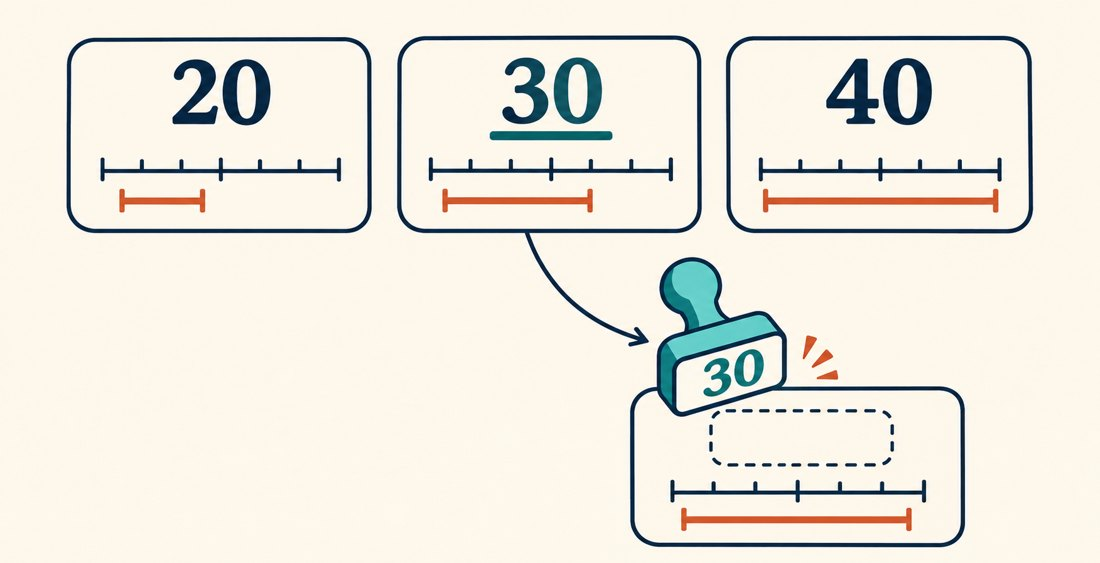

**Visualiser.** Suis la flèche qui part de la carte du milieu. Quel nombre le tampon inscrit-il sur la nouvelle fiche ? Cette opération s’appelle *imputer* une valeur manquante.

**Coder.** Dans la cellule, `pd.DataFrame` crée un tableau avec une ligne par fiche. La colonne `bmi` contient l’IMC (*body mass index* en anglais). La case vide s’écrit `float("nan")`.

Le remplacement est confié à `SimpleImputer`. Sur les trois fiches connues, il calcule et mémorise la médiane avec `fit`. Sur le nouvel arrivage, il remplit les cases vides avec ce nombre quand on appelle `transform`. Les deux lignes `print` affichent la valeur mémorisée, puis les trois IMC du nouvel arrivage.

In [1]:
import pandas as pd
from sklearn.impute import SimpleImputer

connues = pd.DataFrame({"bmi": [20.0, 30.0, 40.0]})
arrivees = pd.DataFrame({"bmi": [float("nan"), 44.0, 46.0]})
remplacement = SimpleImputer(strategy="median").fit(connues)
print("Valeur mémorisée", remplacement.statistics_[0])
print("Trois fiches après remplacement", remplacement.transform(arrivees)[:, 0])

Valeur mémorisée 30.0
Trois fiches après remplacement [30. 44. 46.]


**Pratiquer.** Quelqu’un propose de recalculer la médiane après chaque arrivage. Dans la cellule, `pd.concat` met les fiches connues et le nouvel arrivage bout à bout, puis `.median()` calcule la médiane de ce mélange. Prédis le résultat de cette méthode et celui de la règle apprise plus haut. Change ensuite 44 et 46 en 10 et 12, puis relance seulement cette cellule. Quelle méthode donne deux IMC différents à la même fiche ?

In [2]:
arrivage = pd.DataFrame({"bmi": [float("nan"), 44.0, 46.0]})
toutes = pd.concat([connues, arrivage])
print("Avec toutes les fiches", toutes["bmi"].median())
print("Avec la règle déjà apprise", remplacement.transform(arrivage)[0, 0])

Avec toutes les fiches 40.0
Avec la règle déjà apprise 30.0


<details><summary>Comparer les deux arrivages</summary>

Au premier essai, les cinq valeurs connues sont 20, 30, 40, 44 et 46. Le mélange donne 40. Au second, le mélange donne 20. La règle apprise sur les trois fiches d’origine donne 30 dans les deux cas. Le véritable IMC de la personne reste inconnu.

</details>

**Approfondir.** Si l’arrivage doit servir à évaluer l’arbre, ses valeurs ont déjà influencé la médiane dans la méthode qui mélange les fiches. Une partie des renseignements réservés à l’évaluation a donc servi à préparer les données. C’est une **fuite de données**.

La médiane donne un nombre pour la case IMC. Dans la colonne sur le tabac, une personne a écrit « fume ». Comment transmettre cette réponse à l’arbre sous forme de nombres sans lui donner un rang parmi les réponses possibles ?

### Les réponses sur le tabac

Pour la question sur le tabac, écris trois en-têtes sur un papier, « inconnu », « fume », « n’a jamais fumé ». Une personne répond « fume ». Où écris-tu 1 ? Que mets-tu dans les deux autres cases ?

Chaque en-tête indique la présence ou l’absence d’une réponse. Traduire les mots de cette façon s’appelle un **codage par indicateurs** (*one-hot* en anglais). La cellule le fait avec `OneHotEncoder` et les libellés anglais du fichier. Dans le tableau obtenu, regarde le nom au-dessus de chaque colonne avant de lire les 0 et les 1. Repère les lignes `Unknown` (« inconnu ») et `en_attente` (une réponse qui n’existait pas à l’apprentissage).

In [3]:
from sklearn.preprocessing import OneHotEncoder

tabac = pd.DataFrame({"tabac": ["Unknown", "smokes", "never smoked"]})
codeur = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
codeur.fit(tabac)
essai = pd.DataFrame({"tabac": ["smokes", "Unknown", "en_attente"]})
pd.DataFrame(codeur.transform(essai), columns=codeur.categories_[0], index=essai["tabac"])

,Unknown,never smoked,smokes
tabac,,,
smokes,0.0,0.0,1.0
Unknown,1.0,0.0,0.0
en_attente,0.0,0.0,0.0


`Unknown` est une réponse écrite qui a sa colonne. La réponse `en_attente` arrive après l’apprentissage. Avec `handle_unknown="ignore"`, les indicateurs du tabac restent tous à zéro sur cette ligne.

Pour le tabac, la présence d’un 1 suffit à lire la réponse. Pour l’âge, on conserve la mesure. Comment exprimer qu’une personne se trouve au-dessus ou au-dessous de l’âge moyen des fiches étudiées, et de combien ?

### L’âge par rapport à la moyenne

Quatre personnes ont 40, 40, 60 et 60 ans. La moyenne est de 50 ans. Chacun se trouve ici à 10 ans de la moyenne. Pour ce lot, ces 10 ans correspondent à un **écart-type**, une mesure de la dispersion des âges autour de leur moyenne. Plus les âges s’étalent autour de cette moyenne, plus un écart-type représente d’années.

Prends 10 ans comme unité. Pour situer une personne sur cette échelle, enlève 50 à son âge, puis divise par 10. Exprimer une mesure en nombre d’écarts-types par rapport à la moyenne, c’est la **standardiser**. Combien obtiens-tu pour 40, 50 et 70 ans ? Vérifie avec `StandardScaler`.

In [4]:
from sklearn.preprocessing import StandardScaler

ages_connus = pd.DataFrame({"age": [40.0, 40.0, 60.0, 60.0]})
echelle = StandardScaler().fit(ages_connus)
essai_ages = pd.DataFrame({"age": [40.0, 50.0, 70.0]})
essai_ages["age_en_ecarts_types"] = echelle.transform(essai_ages)[:, 0]
essai_ages

,age,age_en_ecarts_types
0,40.0,-1.0
1,50.0,0.0
2,70.0,2.0


Tu obtiens −1, 0 et 2. À 40 ans, la personne se trouve un écart-type sous la moyenne. Tu sais maintenant lire un âge sur cette échelle, remplacer un IMC manquant et coder une réponse sur le tabac. Sur une fiche qui réunit les trois, comment obtenir la ligne de nombres que l’arbre va lire ?

### Suivre une fiche des archives

Chaque ligne décrit une personne. La colonne `stroke` vaut 1 si un AVC figure au dossier, 0 sinon. C’est la réponse que l’arbre devra apprendre à retrouver, appelée **cible** et notée `y` dans le code. Les renseignements qui serviront à proposer une réponse forment le tableau `X`. L’identifiant du dossier reste à part.

La cellule repliée charge les fiches incluses dans ce cahier. Sépare-les avant tout calcul de médiane ou de moyenne. Garde un cinquième pour juger la règle une fois choisie. Ce lot de **test** reste fermé. Les autres fiches servent à mettre la règle au point. Elles forment le lot de **développement**.

Pour le premier essai, mets de côté un quart de ce dernier lot pour comparer les arbres sur des fiches qu’ils n’auront pas étudiées. C’est la **validation**. Les trois quarts restants servent à apprendre la préparation et les questions de l’arbre. C’est l’**apprentissage**.

Dans le code, `train_test_split` tire les fiches au sort pour chacun de ces deux partages. L’option `stratify` garde à peu près la même proportion de 1 dans les lots. Fixer `random_state` à 42 permet de retrouver le même tirage.

In [5]:
from pathlib import Path
import pandas as pd

def tableau_du_cahier():
    dossier = Path(globals().get("__vsc_ipynb_file__") or ".").parent
    for chemin in [dossier / "donnees_stroke.csv", Path("donnees_stroke.csv")]:
        if chemin.is_file():
            return pd.read_csv(chemin)
    raise FileNotFoundError("donnees_stroke.csv introuvable : place-le à côté du notebook, puis relance cette cellule.")

donnees = tableau_du_cahier()
print(len(donnees), "lignes chargées.")


5110 lignes chargées.


In [6]:
mesures = ["age", "avg_glucose_level", "bmi"]
indicateurs = ["hypertension", "heart_disease"]
textes = ["smoking_status", "work_type"]
X = donnees[mesures + indicateurs + textes]
y = donnees["stroke"]

from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_ap, X_val, y_ap, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=42
)
print("Fiches pour apprendre", len(X_ap), "· pour essayer", len(X_val))

Fiches pour apprendre 3066 · pour essayer 1022


Tu as 3 066 fiches pour apprendre (`X_ap`) et 1 022 pour comparer les arbres (`X_val`). Pour compter les cases vides, `.isna()` les repère, puis `.sum()` les compte.

Sur les fiches d’apprentissage, combien d’IMC manquent ? Pour le tabac, une case vide et le mot « inconnu » donnent-ils le même compte ? Lis ce que teste chacune des deux dernières lignes.

In [7]:
print("Cases IMC vides", X_ap["bmi"].isna().sum())
print("Cases tabac vides", X_ap["smoking_status"].isna().sum())
print("Réponses tabac écrites « Unknown »", (X_ap["smoking_status"] == "Unknown").sum())

Cases IMC vides 139
Cases tabac vides 0
Réponses tabac écrites « Unknown » 932


On trouve 139 IMC vides. Pour le tabac, 932 personnes ont la réponse écrite `Unknown` et zéro case est vide. Assimiler « inconnu » à « n’a jamais fumé » changerait leur réponse.

Comment réunir ces renseignements sur une ligne tout en gardant leur sens ? Une fois la case IMC remplie, l’arbre peut poser sa question dans l’unité d’origine, par exemple « l’IMC dépasse-t-il 30 ? ». Ici, on choisit de changer d’échelle. Ce choix servira dans l’atelier pour comparer des distances qui dépendent de deux mesures exprimées dans des unités différentes. Pour le tabac, on garde la réponse écrite.

| Colonnes | Première opération | Opération suivante |
|---|---|---|
| Âge, glucose moyen, IMC | Remplacer les valeurs manquantes par la médiane de chaque colonne | Standardiser chaque mesure |
| Hypertension (tension artérielle élevée), maladie cardiaque | Si une case manque, employer le 0 ou le 1 le plus fréquent | Garder 0 pour non, 1 pour oui |
| Tabac, emploi | Écrire « Non renseigné » dans les cases vides | Créer une colonne par catégorie observée |

Une suite d’opérations enregistrée dans cet ordre s’appelle un **pipeline**. Dans le code, `make_pipeline` assemble les opérations d’un chemin. `ColumnTransformer` envoie chaque colonne sur son chemin et réunit les résultats. Dans ses parenthèses, repère le nom du chemin, la transformation choisie et les colonnes concernées. La fonction `preparer()` construit une préparation neuve à chaque appel.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

def preparer():
    nombres = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    mots = make_pipeline(
        SimpleImputer(strategy="constant", fill_value="Non renseigné"),
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    )
    return ColumnTransformer([
        ("mesures", nombres, mesures),
        ("indicateurs", SimpleImputer(strategy="most_frequent"), indicateurs),
        ("textes", mots, textes),
    ])

**Pratiquer sur une fiche.** Lance seulement la première cellule. Elle prend la première fiche de validation dont l’IMC manque (`head(1)`). La case vide apparaît sous la forme `NaN`. Lis `smoking_status` pour le tabac et `work_type` pour l’emploi. Quelles réponses écrites recevront un 1 ? L’IMC va-t-il devenir exactement zéro après le changement d’échelle ?

Lance ensuite la seconde cellule. Dans les noms du résultat, la partie avant `__` indique le chemin pris (mesures, indicateurs ou textes). La suite permet de retrouver la colonne. Les valeurs sont arrondies à trois décimales par `round(3)`. La dernière indication, `float64`, précise que Python utilise des nombres à virgule pour ce résultat.

In [9]:
fiche = X_val.loc[X_val["bmi"].isna()].head(1)
fiche

,age,avg_glucose_level,bmi,hypertension,heart_disease,smoking_status,work_type
19,57.0,217.08,NaN,0,1,Unknown,Govt_job


In [10]:
lecture = preparer().fit(X_ap)
ligne = lecture.transform(fiche)[0]
pd.Series(ligne, index=lecture.get_feature_names_out()).round(3)

mesures__age                              0.603
mesures__avg_glucose_level                2.413
mesures__bmi                             -0.112
indicateurs__hypertension                 0.000
indicateurs__heart_disease                1.000
textes__smoking_status_Unknown            1.000
textes__smoking_status_formerly smoked    0.000
textes__smoking_status_never smoked       0.000
textes__smoking_status_smokes             0.000
textes__work_type_Govt_job                1.000
textes__work_type_Never_worked            0.000
textes__work_type_Private                 0.000
textes__work_type_Self-employed           0.000
textes__work_type_children                0.000
dtype: float64

<details><summary>Corrigé · Lire la fiche 19 après préparation</summary>

La fiche porte les réponses `Unknown` (tabac inconnu) et `Govt_job` (emploi dans le secteur public). Leurs colonnes `smoking_status_Unknown` et `work_type_Govt_job` valent 1. L’IMC manquant reçoit la médiane d’apprentissage de 28,1. Une fois standardisé, il vaut environ −0,11. Il faudrait un IMC égal à la **moyenne** pour obtenir zéro. À 57 ans, l’âge de cette personne se situe au-dessus de la moyenne d’apprentissage. Sa valeur standardisée est positive.

</details>

**Retenir.** Pour chaque nouvelle fiche, la préparation garde les médianes, les catégories et les échelles apprises sur le premier lot. Ces règles restent les mêmes jusqu’au prochain `fit`.

La fiche 19 a désormais un nombre dans chaque colonne. Si l’arbre peut poser davantage de questions sur ces colonnes, fera-t-il moins d’erreurs sur les fiches qu’il découvre ?

## Limiter le nombre de questions de l’arbre

**Comprendre.** Un arbre trie une fiche en posant une question, puis éventuellement une autre selon la réponse. La **profondeur maximale** est le nombre de questions qu’on l’autorise à poser sur un même chemin. À la profondeur 1, une seule question doit lui suffire.

**Visualiser.** Les deux séries du graphique comptent les erreurs sur 100 fiches. Les ronds correspondent aux fiches étudiées par l’arbre, les carrés aux fiches gardées pour le comparer. Pars des deux points superposés à gauche. Quand la profondeur augmente, les erreurs évoluent-elles dans le même sens sur les deux lots ?

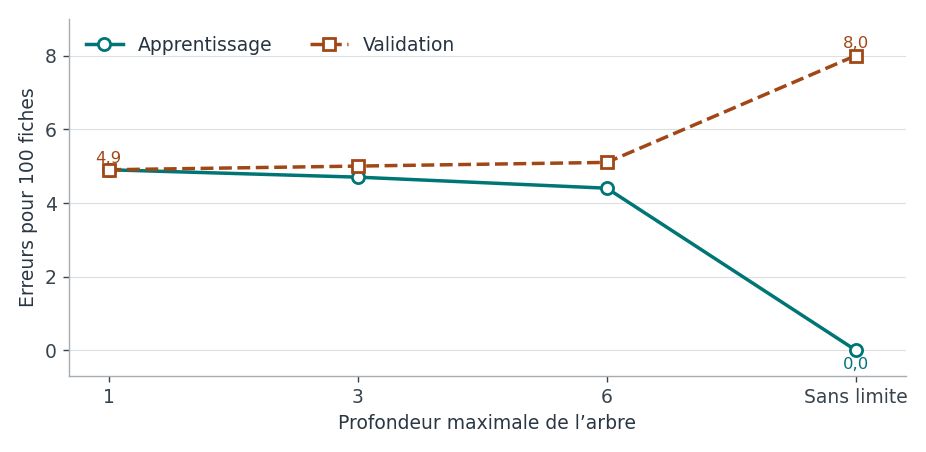

Quand un arbre reproduit de mieux en mieux les exemples étudiés et se trompe davantage sur d’autres fiches, on parle de **surapprentissage**. Un arbre très profond peut aller jusqu’à isoler une fiche et retenir ses particularités.

**Coder.** La première cellule assemble la préparation des fiches et l’arbre qui propose 0 ou 1 (`DecisionTreeClassifier`). La seconde essaie quatre arbres sur les mêmes fiches. Seule la profondeur change. `None` enlève la limite.

Pour compter les erreurs, `predict` propose une réponse pour chaque fiche. La comparaison avec la réponse du dossier compte 1 pour une erreur et 0 pour une réponse juste. Multiplier la moyenne de ces nombres par 100 donne les erreurs pour 100 fiches. Repère dans le tableau la colonne des fiches étudiées et celle des fiches gardées pour la comparaison.

In [11]:
from sklearn.tree import DecisionTreeClassifier

def construire_arbre(profondeur):
    arbre = DecisionTreeClassifier(max_depth=profondeur, random_state=42)
    return make_pipeline(preparer(), arbre)

def erreurs_sur_cent(modele, fiches, reponses):
    return 100 * (modele.predict(fiches) != reponses).mean()

In [12]:
resultats = []
for profondeur in [1, 3, 6, None]:
    candidat = construire_arbre(profondeur).fit(X_ap, y_ap)
    resultats.append({
        "profondeur": str(profondeur) if profondeur is not None else "sans limite",
        "apprentissage": erreurs_sur_cent(candidat, X_ap, y_ap),
        "validation": erreurs_sur_cent(candidat, X_val, y_val),
    })
pd.DataFrame(resultats).round(1)

,profondeur,apprentissage,validation
0,1,4.9,4.9
1,3,4.7,5.0
2,6,4.4,5.1
3,sans limite,0.0,8.0


**Pratiquer.** Compare la profondeur 3 et l’arbre sans limite. Combien d’erreurs pour 100 fiches gagne-t-on sur l’apprentissage ? Combien en perd-on sur la validation ? Dans un lot où environ 5 % des fiches portent un 1, combien d’erreurs ferait une règle qui répond toujours 0 ?

<details><summary>Corrigé · Départager les deux colonnes</summary>

À la profondeur 3, on lit 4,7 erreurs sur 100 en apprentissage et 5,0 en validation. Sans limite, on lit 0 et 8,0. Le gain de 4,7 erreurs sur les fiches connues s’accompagne donc de 3 erreurs supplémentaires sur 100 en validation.

La règle « toujours 0 » manquerait chaque cas positif et ferait environ 5 erreurs sur 100. Pour une équipe qui recherche les dossiers positifs, il faut aussi regarder quelle fraction des dossiers positifs l’arbre retrouve. C’est le rappel du jour 2.

</details>

Sur ce lot de validation, l’arbre de profondeur 3 fait moins d’erreurs que celui sans limite. Gardera-t-il cet avantage si d’autres fiches servent à départager les deux arbres ?

### Approfondir · Changer les fiches qui servent à valider

Réunis les fiches d’apprentissage et de validation du premier essai. Tu retrouves les 4 088 fiches de développement. Répartis-les en cinq paquets. À chaque tour, garde un paquet pour vérifier les réponses et utilise les quatre autres pour apprendre. Chacun de ces paquets s’appelle un **pli**. Chaque paquet contient à peu près la même proportion de dossiers codés 1. Le test reste à part pendant tous ces essais.

| Tour | A | B | C | D | E |
|---|---|---|---|---|---|
| 1 | **Valider** | Apprendre | Apprendre | Apprendre | Apprendre |
| 2 | Apprendre | **Valider** | Apprendre | Apprendre | Apprendre |
| 3 | Apprendre | Apprendre | **Valider** | Apprendre | Apprendre |
| 4 | Apprendre | Apprendre | Apprendre | **Valider** | Apprendre |
| 5 | Apprendre | Apprendre | Apprendre | Apprendre | **Valider** |

Au troisième tour, sur quels paquets calculerais-tu la médiane de l’IMC ? Désigne-les dans le tableau.

<details><summary>Vérifier le troisième tour</summary>

On calcule la médiane sur A, B, D et E. On l’utilise pour remplir les IMC manquants de C. Les catégories, les échelles et l’arbre sont eux aussi réappris sur les quatre paquets de ce tour.

</details>

Au bout des cinq tours, chaque fiche a servi une fois à valider un arbre appris sur d’autres fiches. Cette façon de faire tourner le lot de validation s’appelle la **validation croisée**. Dans le code, `StratifiedKFold` prépare les cinq paquets en gardant des proportions de 1 semblables. Puis `cross_val_score` répète l’apprentissage de la chaîne complète et renvoie un résultat par tour. Avec `scoring="accuracy"`, ce résultat est la proportion de réponses justes. `100 * (1 - score)` le convertit en erreurs pour 100 fiches.

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
erreurs_par_tour = pd.DataFrame(index=range(1, 6))
erreurs_par_tour.index.name = "tour"

for nom, profondeur in [("profondeur 3", 3), ("sans limite", None)]:
    exactitudes = cross_val_score(
        construire_arbre(profondeur), X_dev, y_dev, cv=plis, scoring="accuracy"
    )
    erreurs_par_tour[nom] = 100 * (1 - exactitudes)

display(erreurs_par_tour.round(1))
print("Erreurs moyennes sur 100 fiches")
display(erreurs_par_tour.mean().round(1))

,profondeur 3,sans limite
tour,,
1,4.8,11.2
2,4.9,7.9
3,4.9,7.5
4,4.7,9.9
5,5.0,8.4


Erreurs moyennes sur 100 fiches


profondeur 3    4.8
sans limite     9.0
dtype: float64

**Pratiquer.** Cherche le tour le plus favorable à l’arbre sans limite. Dans ce même tour, quel arbre ferais-tu passer en tête si chaque erreur coûtait autant ? Est-ce aussi celui qui l’emporte sur la moyenne des cinq tours ?

<details><summary>Corrigé · Interpréter les cinq tours</summary>

L’arbre sans limite obtient son minimum au tour 3, avec environ 7,5 erreurs sur 100. L’arbre de profondeur 3 en fait environ 4,9 sur ces mêmes fiches. Il obtient aussi la meilleure moyenne, environ 4,8 contre 9,0. La profondeur 3 fait moins d’erreurs à chacun des cinq tours. Le nombre exact varie selon le paquet gardé pour vérifier les réponses.

</details>

**Retenir.** Pour comparer les réglages, garde les mêmes plis pour les deux arbres et refais la préparation à chaque tour. La moyenne aide à choisir. Tu réserves le test à la règle fixée.

Tu as pu compter les erreurs parce qu’une réponse figurait déjà dans chaque dossier. Un atelier partagé a relevé le nombre et la durée des visites de ses abonnés. Aucun profil ne figure sur leurs fiches. Sur quoi t’appuyer pour regrouper les abonnés qui fréquentent l’atelier de façon semblable ?

## Travaux pratiques · Quels créneaux proposer aux abonnés de l’atelier ?

**Comprendre.** Les relevés d’un mois donnent le nombre de visites et la durée moyenne d’une visite pour chacun des 18 abonnés fictifs. Avant de modifier les créneaux de réservation, la responsable veut savoir quelles habitudes se dégagent.

Former des groupes à partir de ces habitudes s’appelle une **segmentation**. Le calcul reçoit seulement les mesures (le tableau `X`). Comme personne ne lui fournit de profils à retrouver (les réponses `y`), on dit que l’apprentissage est **non supervisé**.

**Visualiser.** Chaque abonné donne un point. Sa position indique son nombre de visites sur l’axe horizontal et leur durée moyenne sur l’axe vertical. Tous ces points forment un **nuage de points**. Choisis deux ou trois zones que tu entourerais sur le graphique. À quoi correspond le point situé à une visite et vingt minutes ?

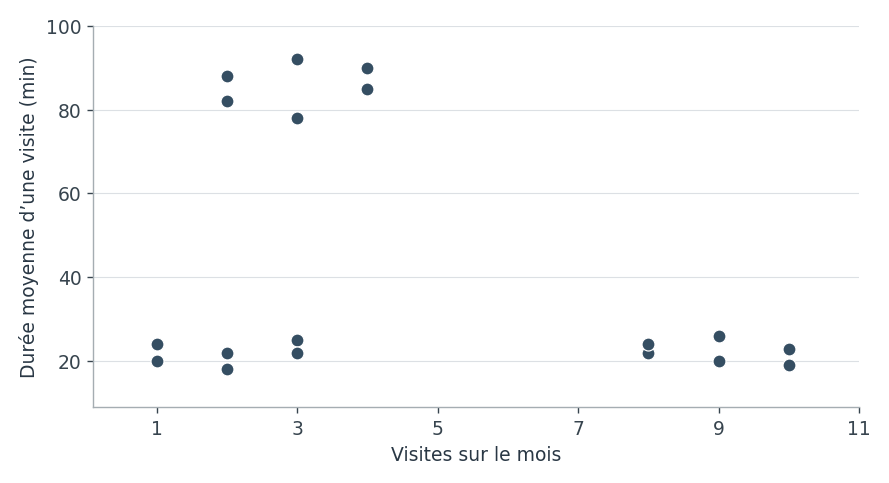

Le point en bas à gauche correspond à une personne venue une seule fois, pour vingt minutes.

Tu as entouré les points qui se ressemblent. Chercher des groupes de cette façon s’appelle le **regroupement**, ou *clustering* en anglais. Quelle règle pourrait attribuer chacun des 18 points à un groupe, y compris près du bord d’une zone ?

**Approfondir.** Imagine trois repères posés sur le nuage, un par groupe souhaité. Le nombre de groupes que tu demandes se note `K`. Ici, `K = 3`.

1. Rattache chaque point au repère le plus proche.
2. Dans chaque groupe, calcule la moyenne des visites et la moyenne des durées. Déplace le repère à ces coordonnées. Il devient le **centre** du groupe.
3. Rattache de nouveau les points au centre le plus proche. Répète jusqu’à ce que les centres se stabilisent.

Ce calcul s’appelle **K-means** (« K moyennes »), car chacun des `K` centres se place aux moyennes de son groupe. Si un groupe provisoire contient seulement les abonnés (1 visite, 20 minutes) et (3 visites, 22 minutes), où déplacerais-tu son centre ?

<details><summary>Vérifier la position du centre</summary>

Le centre se trouve à 2 visites et 21 minutes, les moyennes de 1 et 3, puis de 20 et 22. Il peut se trouver entre deux abonnés.

</details>

Sur le graphique, tu lis les minutes et les visites dans leurs unités habituelles. Pour mesurer la distance entre un point et un centre, les unités posent un problème. Passer des minutes aux secondes multiplierait les écarts de durée par 60, alors que les habitudes des abonnés seraient les mêmes. On standardise donc les visites et les durées séparément, comme pour les âges plus haut. Sur chaque axe, une unité représente alors un écart-type.

**Coder.** Charge les relevés. Par exemple, `(8, 22)` décrit une personne venue huit fois dans le mois, pour une durée moyenne de 22 minutes par visite. Un même abonné produit un seul point. Les numéros d’abonné dans la marge permettent de retrouver une ligne.

In [14]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

releves = [
    (1, 20), (8, 22), (2, 82), (2, 22), (10, 19), (3, 92),
    (3, 25), (9, 26), (2, 88), (1, 24), (8, 24), (4, 85),
    (2, 18), (9, 20), (3, 78), (3, 22), (10, 23), (4, 90),
]
atelier = pd.DataFrame(releves, columns=["visites", "minutes"])
atelier.index = pd.RangeIndex(1, len(atelier) + 1, name="abonné")
mesures_atelier = atelier[["visites", "minutes"]]
atelier.head()

,visites,minutes
abonné,,
1,1,20
2,8,22
3,2,82
4,2,22
5,10,19


La fonction apprend les centres sur les deux mesures standardisées, attribue chaque abonné au centre le plus proche et renvoie un numéro de groupe par abonné. C’est ce que fait `fit_predict`. Comment décrire ensuite chaque groupe à la responsable en visites et en minutes ?

La fonction reporte les numéros de groupe à côté des relevés d’origine (`assign`), rassemble les lignes de même numéro (`groupby`), puis compte les abonnés et calcule les moyennes en visites et en minutes.

Pour mesurer à quel point les abonnés sont proches de leur centre, prends la distance de chacun à son centre sur les deux mesures standardisées. Multiplie chaque distance par elle-même, puis additionne les 18 résultats. Deux points à des distances de 1 et 2 comptent ainsi pour 1 × 1 + 2 × 2 = 5 dans la somme. La somme pour tous les points s’appelle l’**inertie**. La dernière ligne de la fonction la récupère avec `inertia_`. Dans le code, `n_init=10` essaie dix placements de départ pour le même nombre de groupes et garde celui qui donne la plus petite inertie. `random_state=42` permet de répéter l’essai.

In [15]:
def segmenter(k):
    modele = make_pipeline(
        StandardScaler(), KMeans(n_clusters=k, n_init=10, random_state=42)
    )
    numeros = modele.fit_predict(mesures_atelier)
    classement = atelier.assign(groupe=numeros)
    profils = classement.groupby("groupe").agg(
        abonnes=("visites", "size"),
        visites_moyennes=("visites", "mean"),
        minutes_moyennes=("minutes", "mean"),
    )
    return profils, modele[-1].inertia_

**Pratiquer.** La responsable pourrait organiser jusqu’à quatre types de créneaux. En passant de deux groupes à trois, puis à quatre, quelles habitudes jusque-là réunies peux-tu distinguer ?

1. Dans la cellule, le nombre de groupes se règle avec la variable `k`. Lance-la d’abord avec `k = 2`. Combien de personnes se trouvent dans le plus grand groupe ? Repère sur le nuage les durées de visite qu’il réunit.
2. Essaie `k = 3` puis `k = 4`. Pour chaque essai, note le nombre de personnes par groupe et les deux moyennes. Les numéros des groupes sont de simples repères et peuvent changer entre les essais.
3. Compare les inerties des trois essais. De combien l’inertie baisse-t-elle à chaque passage ? Quel usage supplémentaire distingues-tu ?
4. Rédige trois phrases pour la responsable. Donne ton `K`, décris les usages en visites et en minutes, puis propose un essai de réservation dont tu vérifierais l’intérêt auprès des abonnés.

In [16]:
k = 2    # Essaie ensuite 3, puis 4.
profils, inertie = segmenter(k)
display(profils.sort_values(["visites_moyennes", "minutes_moyennes"]).round(1))
print("Inertie", round(inertie, 2))

,abonnes,visites_moyennes,minutes_moyennes
groupe,,,
1,12,2.5,53.8
0,6,9.0,22.3


Inertie 15.13


<details><summary>Indice · Lire le groupe de douze</summary>

Avec deux groupes, repère la moyenne proche de 54 minutes. Cherche les douze abonnés concernés sur le graphique en te guidant par leur nombre de visites. Combien de durées se trouvent réellement autour de 54 minutes ?

</details>

**Ta proposition.** Note ici le nombre de groupes retenu et le créneau à essayer. Si la responsable te demande pourquoi tu as gardé ce nombre de groupes, quels abonnés peux-tu lui montrer sur le graphique ? Rédige ton argument avant de lire le corrigé.

### Corrigé de l’atelier

Avec `K = 2`, les six visiteurs fréquents forment un groupe. Les douze autres viennent en moyenne 2,5 fois et restent 53,8 minutes. Aucun d’eux ne reste près de 54 minutes par visite. Cette moyenne rassemble des passages courts et des visites longues.

Avec `K = 3`, les trois groupes comptent chacun six personnes. Les centres du graphique sont exprimés dans les unités de l’atelier.

| Proposition de nom | Visites moyennes sur le mois | Minutes moyennes par visite |
|---|---:|---:|
| Passages courts et occasionnels | 2 | 21,8 |
| Séances longues et occasionnelles | 3 | 85,8 |
| Passages courts et fréquents | 9 | 22,3 |

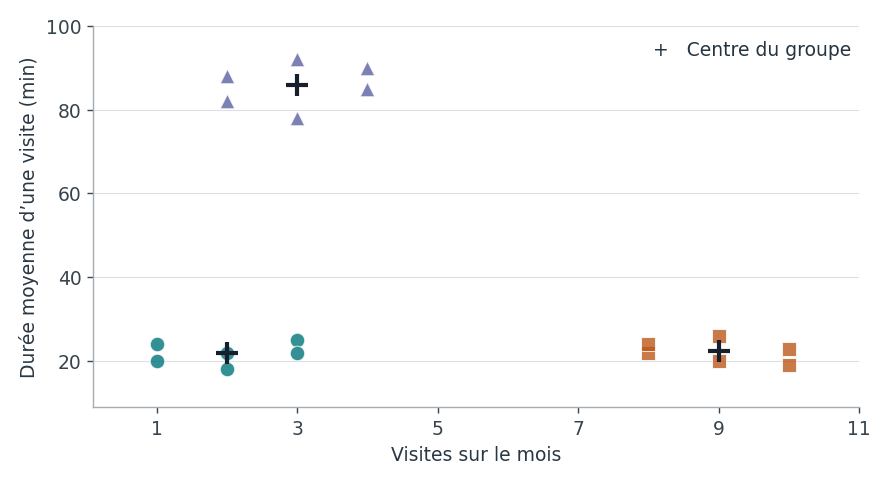

L’inertie passe d’environ 15,13 à 1,40, puis à 1,07. Le troisième groupe réduit donc l’inertie d’environ 13,73 et distingue les séances longues des passages courts. Le quatrième la réduit encore de 0,33. Les deux groupes aux visites courtes gardent chacun leurs six abonnés et les moyennes du tableau. Les six abonnés aux séances longues se séparent en deux groupes de trois. Les premiers viennent en moyenne 2,3 fois pour 82,7 minutes par visite, les autres 3,7 fois pour 89,0 minutes. Ajouter des centres peut toujours réduire les distances. Une baisse seule ne suffit pas à justifier un nouveau type de créneau.

**Une réponse à la responsable.** « Je retiens trois usages sur ce mois. Six abonnés viennent pour des séances d’environ 86 minutes, les douze autres passent environ 22 minutes et se répartissent entre visites occasionnelles et fréquentes. Je proposerais aux six premiers d’essayer une réservation de 90 minutes et je leur demanderais si elle convient à leurs projets. »

Tu peux défendre deux groupes si l’atelier s’intéresse seulement à la fréquence des venues. Dans ce cas, signale que ce choix réunit deux durées très différentes. Pour vérifier si l’organisation envisagée convient à un autre mois, recueille de nouveaux relevés ainsi que l’avis des abonnés.

Dans les archives AVC, tu as compté les erreurs de l’arbre. À l’atelier, tu as défendu un créneau à partir des usages observés. Pour expliquer chacun de ces résultats, quelles fiches ont servi au calcul et de quelle réponse disposais-tu pour le vérifier ?

## Retenir · Avant le projet de contrôle qualité

| Question à te poser | Geste à reproduire |
|---|---|
| Qui a fixé la valeur de remplacement et l’échelle ? | Apprendre la préparation sur les fiches d’apprentissage, puis l’appliquer aux autres. |
| Le modèle s’améliore-t-il sur d’autres fiches ? | Comparer les résultats d’apprentissage et de validation avec la même mesure. |
| L’écart dépend-il d’un seul tirage ? | Réessayer sur plusieurs plis avec la préparation dans le pipeline. Réserver le test à la règle choisie. |
| Quelle réponse apprend-on à prédire ? | Avec une cible, évaluer les prédictions. Sans cible, justifier les groupes par leurs mesures et par la question posée. |

Les groupes d’abonnés décrivent des habitudes de visite. Au jour 4, un atelier industriel dispose du verdict d’inspection de pièces déjà fabriquées. Une fausse alerte et une pièce défectueuse laissée dans la file ordinaire ont des coûts différents. Comment utiliser ces exemples et le coût des erreurs pour décider quelles nouvelles pièces contrôler en priorité ?